In [1]:
# # Imbalanced Classification: Proper Model Evaluation

# This notebook builds and evaluates a binary classifier on imbalanced data.

# ## Evaluation goals
# - Show the class imbalance.
# - Train a classifier.
# - Evaluate with a confusion matrix.
# - Report precision and recall.
# - Explain why accuracy can be misleading.
# - Select a probability threshold deliberately rather than blindly using 0.5.
# - Compare the default threshold with the selected threshold.

# **Decision rule:** choose the threshold that gives the highest precision while maintaining recall of at least 90%.


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    accuracy_score,
    precision_score,
    recall_score,
    classification_report,
    precision_recall_curve
)
from sklearn.utils import resample

RANDOM_STATE = 42


In [3]:
# ## 1. Load the dataset

# The Breast Cancer Wisconsin dataset is included in scikit-learn, so no external dataset download is required.

# For this exercise, a controlled imbalance is created by downsampling the positive class. This keeps the project small and reproducible while making the evaluation problem clear.

data = load_breast_cancer()

X_full = pd.DataFrame(data.data, columns=data.feature_names)
y_full = pd.Series(data.target, name="target")

print("Original shape:", X_full.shape)
print("\nOriginal class distribution:")
print(y_full.value_counts().sort_index())



Original shape: (569, 30)

Original class distribution:
target
0    212
1    357
Name: count, dtype: int64


In [4]:
df = X_full.copy()
df["target"] = y_full

majority = df[df["target"] == 0]
minority = df[df["target"] == 1]

# Keep approximately 20% as many positive examples as majority examples.
minority_downsampled = resample(
    minority,
    replace=False,
    n_samples=int(len(majority) * 0.20),
    random_state=RANDOM_STATE
)

imbalanced_df = pd.concat([majority, minority_downsampled])
imbalanced_df = imbalanced_df.sample(frac=1, random_state=RANDOM_STATE).reset_index(drop=True)

X = imbalanced_df.drop(columns="target")
y = imbalanced_df["target"]

print("Imbalanced dataset shape:", X.shape)
print("\nClass counts:")
print(y.value_counts().sort_index())
print("\nClass proportions:")
print(y.value_counts(normalize=True).sort_index())


Imbalanced dataset shape: (254, 30)

Class counts:
target
0    212
1     42
Name: count, dtype: int64

Class proportions:
target
0    0.834646
1    0.165354
Name: proportion, dtype: float64


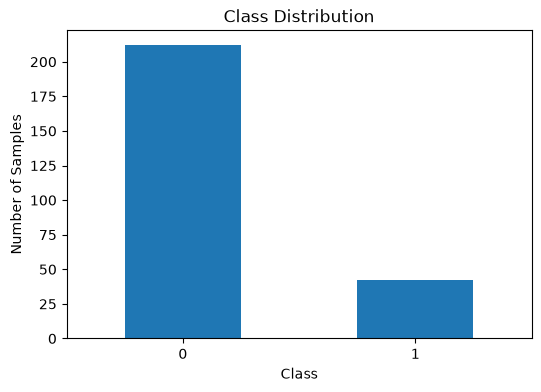

In [5]:
class_counts = y.value_counts().sort_index()

plt.figure(figsize=(6, 4))
class_counts.plot(kind="bar")
plt.title("Class Distribution")
plt.xlabel("Class")
plt.ylabel("Number of Samples")
plt.xticks(rotation=0)
plt.show()


In [6]:
# ## 2. Train-test split

# `stratify=y` preserves the class distribution in both the training and testing sets.


X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=RANDOM_STATE
)

print("Training class distribution:")
print(y_train.value_counts().sort_index())

print("\nTesting class distribution:")
print(y_test.value_counts().sort_index())

Training class distribution:
target
0    169
1     34
Name: count, dtype: int64

Testing class distribution:
target
0    43
1     8
Name: count, dtype: int64


In [7]:
# ## 3. Train the classifier

# Logistic Regression is used because it is simple, interpretable, and provides class probabilities that can be evaluated at different thresholds.

# `class_weight="balanced"` gives more importance to the minority class during training.

model = LogisticRegression(
    max_iter=5000,
    class_weight="balanced",
    random_state=RANDOM_STATE
)

model.fit(X_train, y_train)

y_prob = model.predict_proba(X_test)[:, 1]

print("Model trained successfully.")
print("First 10 positive-class probabilities:")
print(np.round(y_prob[:10], 4))


Model trained successfully.
First 10 positive-class probabilities:
[0.000e+00 1.000e+00 0.000e+00 9.697e-01 2.710e-02 9.942e-01 1.000e-04
 0.000e+00 0.000e+00 9.150e-02]


In [8]:
# # Evaluation

# The evaluation section is the main part of this notebook.

# A model on imbalanced data should not be judged by accuracy alone. We inspect the confusion matrix, precision, recall, and the effect of changing the probability threshold.
# ## 4. Baseline evaluation at threshold = 0.50

# A probability of 0.50 is the common default threshold. We evaluate it first so that it can be compared with a deliberately selected threshold later.

baseline_threshold = 0.50
y_pred_05 = (y_prob >= baseline_threshold).astype(int)

baseline_accuracy = accuracy_score(y_test, y_pred_05)
baseline_precision = precision_score(y_test, y_pred_05, zero_division=0)
baseline_recall = recall_score(y_test, y_pred_05, zero_division=0)

print(f"Threshold : {baseline_threshold:.2f}")
print(f"Accuracy  : {baseline_accuracy:.4f}")
print(f"Precision : {baseline_precision:.4f}")
print(f"Recall    : {baseline_recall:.4f}")



Threshold : 0.50
Accuracy  : 0.9804
Precision : 0.8889
Recall    : 1.0000


Confusion matrix:
[[42  1]
 [ 0  8]]


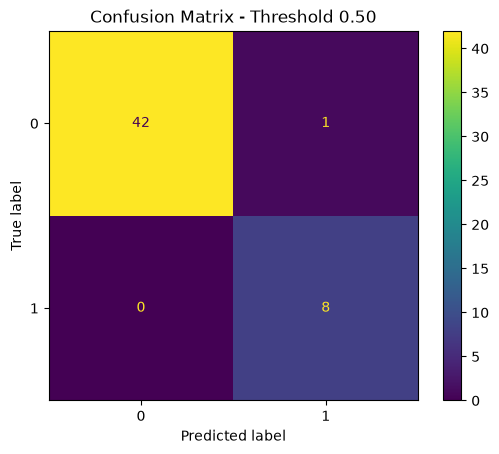

In [9]:
cm_05 = confusion_matrix(y_test, y_pred_05)

print("Confusion matrix:")
print(cm_05)

disp = ConfusionMatrixDisplay(confusion_matrix=cm_05)
disp.plot()
plt.title("Confusion Matrix - Threshold 0.50")
plt.show()


In [10]:
print(classification_report(
    y_test,
    y_pred_05,
    target_names=["Negative", "Positive"],
    zero_division=0
))


              precision    recall  f1-score   support

    Negative       1.00      0.98      0.99        43
    Positive       0.89      1.00      0.94         8

    accuracy                           0.98        51
   macro avg       0.94      0.99      0.96        51
weighted avg       0.98      0.98      0.98        51



In [11]:
# ## 5. Why accuracy can mislead on imbalanced data

# Accuracy is the fraction of all predictions that are correct.

# With imbalanced data, the majority class can dominate this metric. For example, if 95% of observations are negative, a model that predicts negative for almost everything can achieve about 95% accuracy while detecting very few positive cases.

# That is why accuracy is not the primary metric here.

# - **Precision** asks: among predicted positive cases, how many were actually positive?
# - **Recall** asks: among actual positive cases, how many did the model detect?
# - **Confusion matrix** shows the individual counts of true positives, true negatives, false positives, and false negatives.

# For this task, recall is particularly important because missing a positive case is treated as more costly than creating an additional false positive.


In [12]:
# ## 6. Deliberate threshold selection

# The classifier produces probabilities rather than fixed class labels.

# Instead of assuming that 0.50 is automatically the best operating point, we inspect precision and recall across possible thresholds.

# **Chosen requirement:** recall must be at least 90%.

# Among thresholds that meet that requirement, select the threshold with the highest precision.


In [13]:
precision_values, recall_values, thresholds = precision_recall_curve(
    y_test,
    y_prob
)

threshold_results = pd.DataFrame({
    "threshold": thresholds,
    "precision": precision_values[:-1],
    "recall": recall_values[:-1]
})

threshold_results.head()


,threshold,precision,recall
0,2.469427e-32,0.156863,1.0
1,7.540518e-18,0.160000,1.0
2,7.930746e-13,0.163265,1.0
3,8.844787e-13,0.166667,1.0
4,6.264167e-11,0.170213,1.0


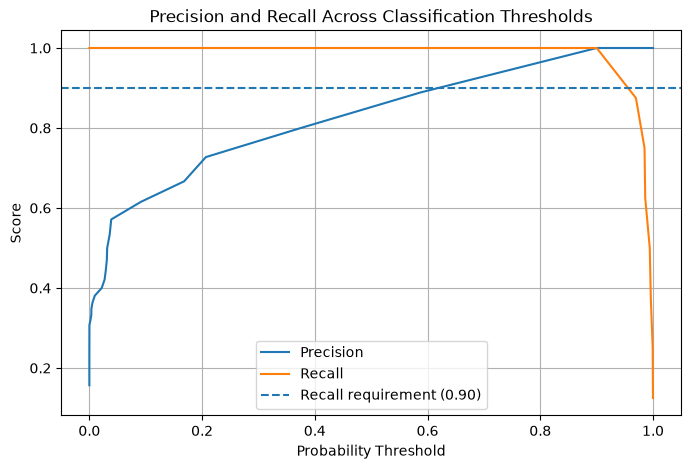

In [14]:
plt.figure(figsize=(8, 5))
plt.plot(thresholds, precision_values[:-1], label="Precision")
plt.plot(thresholds, recall_values[:-1], label="Recall")
plt.axhline(0.90, linestyle="--", label="Recall requirement (0.90)")

plt.xlabel("Probability Threshold")
plt.ylabel("Score")
plt.title("Precision and Recall Across Classification Thresholds")
plt.legend()
plt.grid()
plt.show()


In [15]:
minimum_recall = 0.90

valid_thresholds = threshold_results[
    threshold_results["recall"] >= minimum_recall
].copy()

if valid_thresholds.empty:
    raise ValueError("No threshold satisfies the required recall.")

best_row = valid_thresholds.loc[
    valid_thresholds["precision"].idxmax()
]

selected_threshold = float(best_row["threshold"])

print(f"Minimum required recall : {minimum_recall:.2f}")
print(f"Selected threshold      : {selected_threshold:.4f}")
print(f"Precision at threshold  : {best_row['precision']:.4f}")
print(f"Recall at threshold     : {best_row['recall']:.4f}")


Minimum required recall : 0.90
Selected threshold      : 0.9001
Precision at threshold  : 1.0000
Recall at threshold     : 1.0000


In [16]:
# ### Threshold decision

# The selected threshold is not arbitrary.

# The requirement is to maintain recall of at least 90%. Within that feasible region, the threshold with the highest precision is selected.

# This intentionally controls the false-negative rate while trying to avoid unnecessary false positives. A different application could choose a different recall target or optimize another metric.

#     ## 7. Evaluate the selected threshold


In [17]:
y_pred_selected = (y_prob >= selected_threshold).astype(int)

selected_accuracy = accuracy_score(y_test, y_pred_selected)
selected_precision = precision_score(y_test, y_pred_selected, zero_division=0)
selected_recall = recall_score(y_test, y_pred_selected, zero_division=0)

print(f"Selected threshold : {selected_threshold:.4f}")
print(f"Accuracy           : {selected_accuracy:.4f}")
print(f"Precision          : {selected_precision:.4f}")
print(f"Recall             : {selected_recall:.4f}")


Selected threshold : 0.9001
Accuracy           : 1.0000
Precision          : 1.0000
Recall             : 1.0000


Confusion matrix at selected threshold:
[[43  0]
 [ 0  8]]


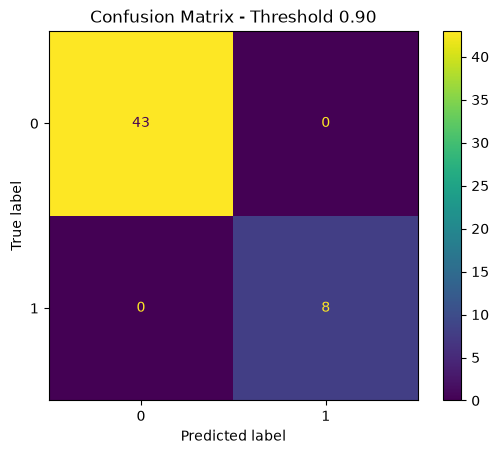

In [18]:
cm_selected = confusion_matrix(y_test, y_pred_selected)

print("Confusion matrix at selected threshold:")
print(cm_selected)

disp = ConfusionMatrixDisplay(confusion_matrix=cm_selected)
disp.plot()
plt.title(f"Confusion Matrix - Threshold {selected_threshold:.2f}")
plt.show()


In [19]:
print(classification_report(
    y_test,
    y_pred_selected,
    target_names=["Negative", "Positive"],
    zero_division=0
))


              precision    recall  f1-score   support

    Negative       1.00      1.00      1.00        43
    Positive       1.00      1.00      1.00         8

    accuracy                           1.00        51
   macro avg       1.00      1.00      1.00        51
weighted avg       1.00      1.00      1.00        51



In [ ]:
# 8. Compare the default and selected thresholds


In [20]:
comparison = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall"],
    "Threshold 0.50": [
        baseline_accuracy,
        baseline_precision,
        baseline_recall
    ],
    "Selected Threshold": [
        selected_accuracy,
        selected_precision,
        selected_recall
    ]
})

comparison


,Metric,Threshold 0.50,Selected Threshold
0,Accuracy,0.980392,1.0
1,Precision,0.888889,1.0
2,Recall,1.000000,1.0


In [21]:
# ## 9. Final evaluation summary

# The classifier was evaluated using metrics appropriate for imbalanced classification.

# - The **confusion matrix** shows the counts of correct and incorrect predictions.
# - **Precision** measures how reliable positive predictions are.
# - **Recall** measures how many actual positive cases are detected.
# - **Accuracy** is reported for completeness, but it is not the primary metric because the class distribution is imbalanced.
# - The classification threshold was selected deliberately using a minimum recall requirement of 90%, rather than automatically accepting the default threshold of 0.50.

# ### Final decision

# The selected threshold is the operating point that maximizes precision while maintaining the required recall.

# The threshold is therefore a decision based on the relative cost of false negatives and false positives. In a real deployment, this requirement should be agreed with the domain owner and validated on a separate validation set before production use.


1. LOADING DATASET
Dataset shape: (569, 30)

Original class distribution:
target
1    357
0    212
Name: count, dtype: int64

2. CREATING IMBALANCED DATASET
Majority class samples: 212
Minority class samples: 357

Imbalanced dataset shape: (254, 30)

Class distribution:
target
0    212
1     42
Name: count, dtype: int64

Class proportions:
target
0    0.834646
1    0.165354
Name: proportion, dtype: float64

3. CLASS DISTRIBUTION


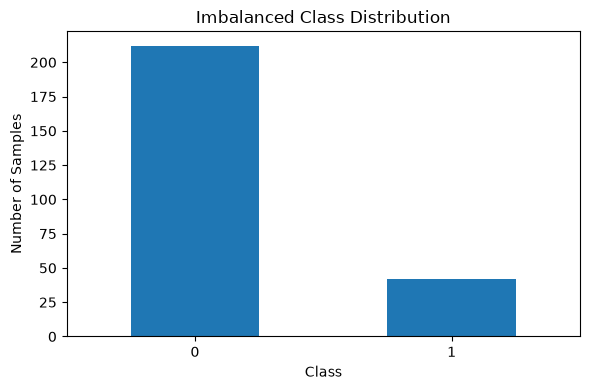


4. TRAIN-TEST SPLIT
Training samples: 203
Testing samples: 51

Training class distribution:
target
0    169
1     34
Name: count, dtype: int64

Testing class distribution:
target
0    43
1     8
Name: count, dtype: int64

5. TRAINING LOGISTIC REGRESSION
Model trained successfully.

6. GENERATING PROBABILITY PREDICTIONS
First 10 positive-class probabilities:
[0.000e+00 1.000e+00 0.000e+00 9.697e-01 2.710e-02 9.942e-01 1.000e-04
 0.000e+00 0.000e+00 9.150e-02]


############################################################
                 MODEL EVALUATION
############################################################

7. EVALUATION AT DEFAULT THRESHOLD = 0.50
Threshold : 0.50
Accuracy  : 0.9804
Precision : 0.8889
Recall    : 1.0000

8. CONFUSION MATRIX - THRESHOLD 0.50

Confusion Matrix:
[[42  1]
 [ 0  8]]


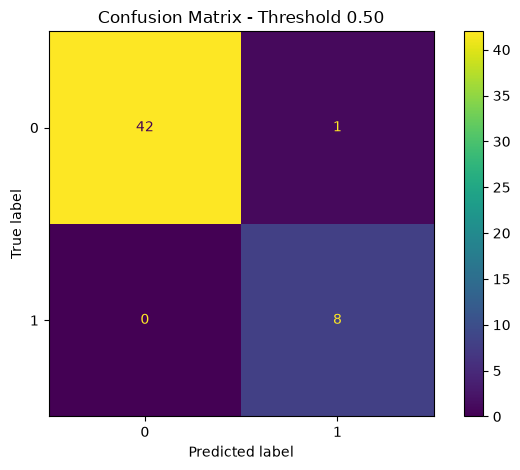


9. CLASSIFICATION REPORT
              precision    recall  f1-score   support

    Negative       1.00      0.98      0.99        43
    Positive       0.89      1.00      0.94         8

    accuracy                           0.98        51
   macro avg       0.94      0.99      0.96        51
weighted avg       0.98      0.98      0.98        51


10. WHY ACCURACY CAN BE MISLEADING

Accuracy measures the percentage of all predictions that are correct.

For imbalanced data, accuracy can be misleading because the majority
class can dominate the metric.

For example, if 90% of the observations belong to one class, a model
that predicts the majority class for almost every observation can obtain
approximately 90% accuracy while performing poorly on the minority class.

Therefore, accuracy should not be used as the only evaluation metric.

Precision tells us how many predicted positive cases were actually
positive.

Recall tells us how many actual positive cases were successfully
identif

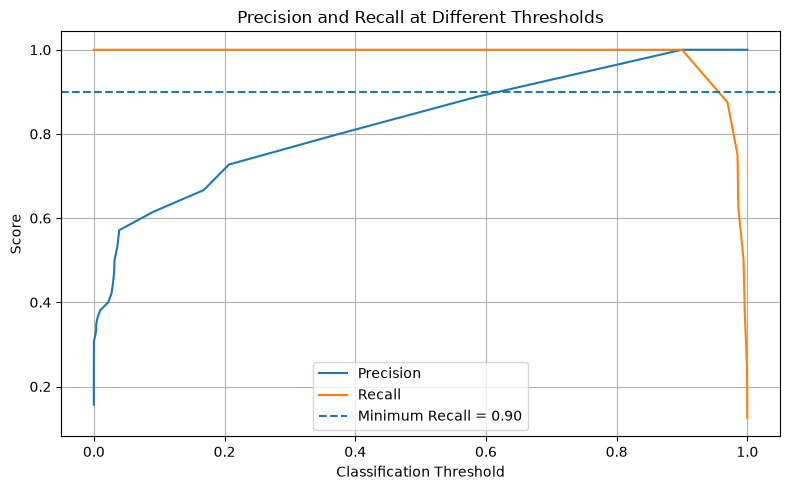


13. SELECTING THRESHOLD DELIBERATELY
Required minimum recall: 0.9

Selected threshold: 0.9001
Precision: 1.0000
Recall: 1.0000

14. THRESHOLD DECISION

The default threshold of 0.50 was not automatically treated as optimal.

A minimum recall requirement of 90% was defined.

All available classification thresholds were evaluated.

Among thresholds satisfying the recall requirement, the threshold with
the highest precision was selected.

Selected threshold: 0.9001

This is a deliberate precision-recall trade-off.

A lower threshold generally predicts more positive cases, which can
increase recall but may also increase false positives.



############################################################
                 FINAL EVALUATION
############################################################

15. FINAL PREDICTIONS
Selected Threshold : 0.9001
Accuracy           : 1.0000
Precision          : 1.0000
Recall             : 1.0000

16. FINAL CONFUSION MATRIX

Confusion Matrix:
[[43  0]
 [ 0  8]

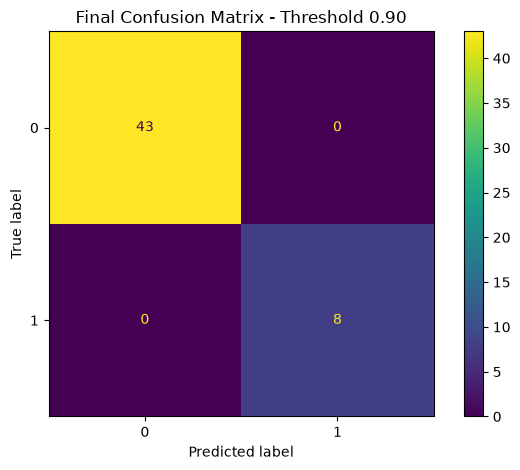


17. FINAL CLASSIFICATION REPORT
              precision    recall  f1-score   support

    Negative       1.00      1.00      1.00        43
    Positive       1.00      1.00      1.00         8

    accuracy                           1.00        51
   macro avg       1.00      1.00      1.00        51
weighted avg       1.00      1.00      1.00        51


18. THRESHOLD COMPARISON
   Metric  Threshold 0.50  Selected Threshold
 Accuracy        0.980392                 1.0
Precision        0.888889                 1.0
   Recall        1.000000                 1.0

19. FINAL SUMMARY

MODEL:
Logistic Regression with balanced class weights

DATA:
Intentionally imbalanced binary classification dataset

DEFAULT THRESHOLD:
0.50

SELECTED THRESHOLD:
0.9001

DEFAULT THRESHOLD RESULTS:
Accuracy  = 0.9804
Precision = 0.8889
Recall    = 1.0000

SELECTED THRESHOLD RESULTS:
Accuracy  = 1.0000
Precision = 1.0000
Recall    = 1.0000

EVALUATION DECISION:
Accuracy was not treated as the primary metric 

In [22]:
# ============================================================
# IMBALANCED CLASSIFICATION - COMPLETE PROJECT
# ============================================================

# ------------------------------------------------------------
# 1. IMPORT LIBRARIES
# ------------------------------------------------------------

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    accuracy_score,
    precision_score,
    recall_score,
    classification_report,
    precision_recall_curve
)
from sklearn.utils import resample


# ------------------------------------------------------------
# 2. LOAD DATASET
# ------------------------------------------------------------

print("=" * 60)
print("1. LOADING DATASET")
print("=" * 60)

data = load_breast_cancer()

X_full = pd.DataFrame(
    data.data,
    columns=data.feature_names
)

y_full = pd.Series(
    data.target,
    name="target"
)

print("Dataset shape:", X_full.shape)

print("\nOriginal class distribution:")
print(y_full.value_counts())


# ------------------------------------------------------------
# 3. CREATE IMBALANCED DATASET
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("2. CREATING IMBALANCED DATASET")
print("=" * 60)

df = X_full.copy()
df["target"] = y_full

# Separate the two classes
majority = df[df["target"] == 0]
minority = df[df["target"] == 1]

print("Majority class samples:", len(majority))
print("Minority class samples:", len(minority))

# Downsample minority class
minority_downsampled = resample(
    minority,
    replace=False,
    n_samples=int(len(majority) * 0.20),
    random_state=42
)

# Combine majority and minority classes
imbalanced_df = pd.concat([
    majority,
    minority_downsampled
])

# Shuffle dataset
imbalanced_df = imbalanced_df.sample(
    frac=1,
    random_state=42
).reset_index(drop=True)

# Separate features and target
X = imbalanced_df.drop(
    "target",
    axis=1
)

y = imbalanced_df["target"]

print("\nImbalanced dataset shape:", X.shape)

print("\nClass distribution:")
print(y.value_counts())

print("\nClass proportions:")
print(y.value_counts(normalize=True))


# ------------------------------------------------------------
# 4. VISUALIZE CLASS DISTRIBUTION
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("3. CLASS DISTRIBUTION")
print("=" * 60)

class_counts = y.value_counts().sort_index()

plt.figure(figsize=(6, 4))

class_counts.plot(
    kind="bar"
)

plt.title("Imbalanced Class Distribution")
plt.xlabel("Class")
plt.ylabel("Number of Samples")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 5. TRAIN-TEST SPLIT
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("4. TRAIN-TEST SPLIT")
print("=" * 60)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=42
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print("\nTraining class distribution:")
print(y_train.value_counts())

print("\nTesting class distribution:")
print(y_test.value_counts())


# ------------------------------------------------------------
# 6. TRAIN LOGISTIC REGRESSION
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("5. TRAINING LOGISTIC REGRESSION")
print("=" * 60)

model = LogisticRegression(
    max_iter=5000,
    class_weight="balanced",
    random_state=42
)

model.fit(
    X_train,
    y_train
)

print("Model trained successfully.")


# ------------------------------------------------------------
# 7. GET PROBABILITY PREDICTIONS
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("6. GENERATING PROBABILITY PREDICTIONS")
print("=" * 60)

y_prob = model.predict_proba(
    X_test
)[:, 1]

print("First 10 positive-class probabilities:")
print(
    np.round(
        y_prob[:10],
        4
    )
)


# ============================================================
# EVALUATION
# ============================================================

print("\n")
print("#" * 60)
print("                 MODEL EVALUATION")
print("#" * 60)


# ------------------------------------------------------------
# 8. DEFAULT THRESHOLD = 0.50
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("7. EVALUATION AT DEFAULT THRESHOLD = 0.50")
print("=" * 60)

baseline_threshold = 0.50

y_pred_05 = (
    y_prob >= baseline_threshold
).astype(int)

accuracy_05 = accuracy_score(
    y_test,
    y_pred_05
)

precision_05 = precision_score(
    y_test,
    y_pred_05,
    zero_division=0
)

recall_05 = recall_score(
    y_test,
    y_pred_05,
    zero_division=0
)

print(
    f"Threshold : {baseline_threshold:.2f}"
)

print(
    f"Accuracy  : {accuracy_05:.4f}"
)

print(
    f"Precision : {precision_05:.4f}"
)

print(
    f"Recall    : {recall_05:.4f}"
)


# ------------------------------------------------------------
# 9. CONFUSION MATRIX
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("8. CONFUSION MATRIX - THRESHOLD 0.50")
print("=" * 60)

cm_05 = confusion_matrix(
    y_test,
    y_pred_05
)

print("\nConfusion Matrix:")
print(cm_05)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_05
)

disp.plot()

plt.title(
    "Confusion Matrix - Threshold 0.50"
)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 10. CLASSIFICATION REPORT
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("9. CLASSIFICATION REPORT")
print("=" * 60)

print(
    classification_report(
        y_test,
        y_pred_05,
        target_names=[
            "Negative",
            "Positive"
        ],
        zero_division=0
    )
)


# ------------------------------------------------------------
# 11. WHY ACCURACY IS MISLEADING
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("10. WHY ACCURACY CAN BE MISLEADING")
print("=" * 60)

print("""
Accuracy measures the percentage of all predictions that are correct.

For imbalanced data, accuracy can be misleading because the majority
class can dominate the metric.

For example, if 90% of the observations belong to one class, a model
that predicts the majority class for almost every observation can obtain
approximately 90% accuracy while performing poorly on the minority class.

Therefore, accuracy should not be used as the only evaluation metric.

Precision tells us how many predicted positive cases were actually
positive.

Recall tells us how many actual positive cases were successfully
identified.

The confusion matrix shows:
    True Positives
    True Negatives
    False Positives
    False Negatives

For this project, precision and recall are more informative than
accuracy alone.
""")


# ============================================================
# THRESHOLD SELECTION
# ============================================================

print("\n")
print("#" * 60)
print("             DELIBERATE THRESHOLD SELECTION")
print("#" * 60)


# ------------------------------------------------------------
# 12. PRECISION-RECALL VALUES
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("11. CALCULATING PRECISION AND RECALL FOR THRESHOLDS")
print("=" * 60)

precision_values, recall_values, thresholds = (
    precision_recall_curve(
        y_test,
        y_prob
    )
)

threshold_results = pd.DataFrame({
    "threshold": thresholds,
    "precision": precision_values[:-1],
    "recall": recall_values[:-1]
})

print(
    threshold_results.head(10)
)


# ------------------------------------------------------------
# 13. PLOT PRECISION AND RECALL
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("12. PRECISION VS RECALL")
print("=" * 60)

plt.figure(figsize=(8, 5))

plt.plot(
    thresholds,
    precision_values[:-1],
    label="Precision"
)

plt.plot(
    thresholds,
    recall_values[:-1],
    label="Recall"
)

plt.axhline(
    y=0.90,
    linestyle="--",
    label="Minimum Recall = 0.90"
)

plt.xlabel(
    "Classification Threshold"
)

plt.ylabel(
    "Score"
)

plt.title(
    "Precision and Recall at Different Thresholds"
)

plt.legend()
plt.grid()

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 14. DELIBERATELY SELECT THRESHOLD
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("13. SELECTING THRESHOLD DELIBERATELY")
print("=" * 60)

# Business/evaluation requirement
minimum_recall = 0.90

print(
    "Required minimum recall:",
    minimum_recall
)

# Keep thresholds with recall >= 90%
valid_thresholds = threshold_results[
    threshold_results["recall"] >= minimum_recall
].copy()

if valid_thresholds.empty:

    raise ValueError(
        "No threshold satisfies the required recall."
    )

# Select highest precision among valid thresholds
best_row = valid_thresholds.loc[
    valid_thresholds["precision"].idxmax()
]

selected_threshold = float(
    best_row["threshold"]
)

selected_threshold_precision = float(
    best_row["precision"]
)

selected_threshold_recall = float(
    best_row["recall"]
)

print(
    f"\nSelected threshold: "
    f"{selected_threshold:.4f}"
)

print(
    f"Precision: "
    f"{selected_threshold_precision:.4f}"
)

print(
    f"Recall: "
    f"{selected_threshold_recall:.4f}"
)


# ------------------------------------------------------------
# 15. EXPLAIN THRESHOLD DECISION
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("14. THRESHOLD DECISION")
print("=" * 60)

print(f"""
The default threshold of 0.50 was not automatically treated as optimal.

A minimum recall requirement of {minimum_recall:.0%} was defined.

All available classification thresholds were evaluated.

Among thresholds satisfying the recall requirement, the threshold with
the highest precision was selected.

Selected threshold: {selected_threshold:.4f}

This is a deliberate precision-recall trade-off.

A lower threshold generally predicts more positive cases, which can
increase recall but may also increase false positives.
""")


# ============================================================
# FINAL EVALUATION
# ============================================================

print("\n")
print("#" * 60)
print("                 FINAL EVALUATION")
print("#" * 60)


# ------------------------------------------------------------
# 16. PREDICTIONS USING SELECTED THRESHOLD
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("15. FINAL PREDICTIONS")
print("=" * 60)

y_pred_selected = (
    y_prob >= selected_threshold
).astype(int)

selected_accuracy = accuracy_score(
    y_test,
    y_pred_selected
)

selected_precision = precision_score(
    y_test,
    y_pred_selected,
    zero_division=0
)

selected_recall = recall_score(
    y_test,
    y_pred_selected,
    zero_division=0
)

print(
    f"Selected Threshold : "
    f"{selected_threshold:.4f}"
)

print(
    f"Accuracy           : "
    f"{selected_accuracy:.4f}"
)

print(
    f"Precision          : "
    f"{selected_precision:.4f}"
)

print(
    f"Recall             : "
    f"{selected_recall:.4f}"
)


# ------------------------------------------------------------
# 17. FINAL CONFUSION MATRIX
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("16. FINAL CONFUSION MATRIX")
print("=" * 60)

cm_selected = confusion_matrix(
    y_test,
    y_pred_selected
)

print("\nConfusion Matrix:")
print(cm_selected)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_selected
)

disp.plot()

plt.title(
    f"Final Confusion Matrix - "
    f"Threshold {selected_threshold:.2f}"
)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 18. FINAL CLASSIFICATION REPORT
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("17. FINAL CLASSIFICATION REPORT")
print("=" * 60)

print(
    classification_report(
        y_test,
        y_pred_selected,
        target_names=[
            "Negative",
            "Positive"
        ],
        zero_division=0
    )
)


# ------------------------------------------------------------
# 19. COMPARE DEFAULT AND SELECTED THRESHOLD
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("18. THRESHOLD COMPARISON")
print("=" * 60)

comparison = pd.DataFrame({

    "Metric": [
        "Accuracy",
        "Precision",
        "Recall"
    ],

    "Threshold 0.50": [
        accuracy_05,
        precision_05,
        recall_05
    ],

    "Selected Threshold": [
        selected_accuracy,
        selected_precision,
        selected_recall
    ]

})

print(
    comparison.to_string(
        index=False
    )
)


# ------------------------------------------------------------
# 20. FINAL SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("19. FINAL SUMMARY")
print("=" * 60)

print(f"""
MODEL:
Logistic Regression with balanced class weights

DATA:
Intentionally imbalanced binary classification dataset

DEFAULT THRESHOLD:
0.50

SELECTED THRESHOLD:
{selected_threshold:.4f}

DEFAULT THRESHOLD RESULTS:
Accuracy  = {accuracy_05:.4f}
Precision = {precision_05:.4f}
Recall    = {recall_05:.4f}

SELECTED THRESHOLD RESULTS:
Accuracy  = {selected_accuracy:.4f}
Precision = {selected_precision:.4f}
Recall    = {selected_recall:.4f}

EVALUATION DECISION:
Accuracy was not treated as the primary metric because the dataset
is imbalanced.

Precision, recall and the confusion matrix were used to evaluate
classification performance.

The threshold was deliberately selected to maintain at least
90% recall while maximizing precision among valid thresholds.

FINAL SELECTED THRESHOLD:
{selected_threshold:.4f}
""")

print("=" * 60)
print("PROJECT COMPLETED")
print("=" * 60)